In [1]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find project root by locating the data folder
current = Path.cwd().resolve()

ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "data").is_dir() and (p / "src").is_dir()),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate project root containing data/ and src/"
    )

os.chdir(ROOT)

# Project directories
DATA_DIR = ROOT / "data"
SRC_DIR = ROOT / "src"
RESULTS_DIR = ROOT / "results"
SUBMISSIONS_DIR = ROOT / "submissions"

print("Project root:", ROOT)
print("Working directory:", Path.cwd())
print("Data directory:", DATA_DIR)

Project root: C:\Users\aatiq\Downloads\latest_changes\fleet_maintenance_p2_team38
Working directory: C:\Users\aatiq\Downloads\latest_changes\fleet_maintenance_p2_team38
Data directory: C:\Users\aatiq\Downloads\latest_changes\fleet_maintenance_p2_team38\data


In [2]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (56000, 174)
Test: (20000, 171)


### Exploratory Data Analysis (EDA):

#### 1. Basic Data Inspection and Missing-Values Analysis:

In [3]:
print("Training information:")
train_df.info()

print("\nTest information:")
test_df.info()

print("\nMissing values in training data:")
display(train_df.isnull().sum().sort_values(ascending=False).head(20))

print("\nMissing values in test data:")
display(test_df.isnull().sum().sort_values(ascending=False).head(20))

print("\nFailure distribution:")
display(train_df["failure"].value_counts(normalize=True) * 100)

print("\nRepair cost statistics:")
display(train_df["repair_cost"].describe())

Training information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56000 entries, 0 to 55999
Columns: 174 entries, id to s169
dtypes: float64(171), int64(2), object(1)
memory usage: 74.3+ MB

Test information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Columns: 171 entries, id to s169
dtypes: float64(170), object(1)
memory usage: 26.1+ MB

Missing values in training data:


repair_cost    55603
s166           46281
s108           45771
s121           44864
s100           43587
s021           43335
s147           43335
s072           41390
s074           37224
s078           25623
s010           21603
s036           13757
s002           13757
s169           13757
s125           13757
s150           13757
s093           12829
s076           12829
s090           12829
s095           12829
dtype: int64


Missing values in test data:


s047    20000
s166    16112
s108    15932
s121    15597
s021    15357
s147    15357
s100    15122
s072    14332
s074    12871
s078     8880
s010     7525
s036     5085
s169     5085
s125     5085
s002     5085
s150     5085
s070     4697
s076     4697
s095     4697
s093     4697
dtype: int64


Failure distribution:


failure
0    99.291071
1     0.708929
Name: proportion, dtype: float64


Repair cost statistics:


count     397.000000
mean      492.382872
std       993.732983
min         5.000000
25%        71.000000
50%       176.000000
75%       488.000000
max      8000.000000
Name: repair_cost, dtype: float64

#### 2. Failure and Repair Costs Analysis:

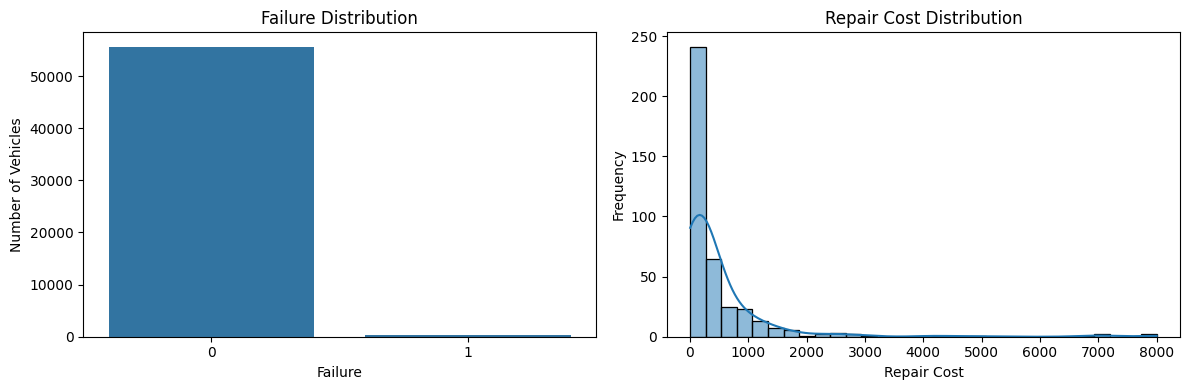

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=train_df, x="failure", ax=axes[0])
axes[0].set_title("Failure Distribution")
axes[0].set_xlabel("Failure")
axes[0].set_ylabel("Number of Vehicles")

sns.histplot(train_df.loc[train_df["failure"] == 1, "repair_cost"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Repair Cost Distribution")
axes[1].set_xlabel("Repair Cost")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

#### 3. Sensor Missing-Values Analysis:

In [5]:
sensor_cols = [col for col in train_df.columns if col.startswith("s")]

print("Number of sensor columns:", len(sensor_cols))

Number of sensor columns: 170


Total missing sensor values:
Train: 787984
Test: 310475


<Figure size 1200x500 with 0 Axes>

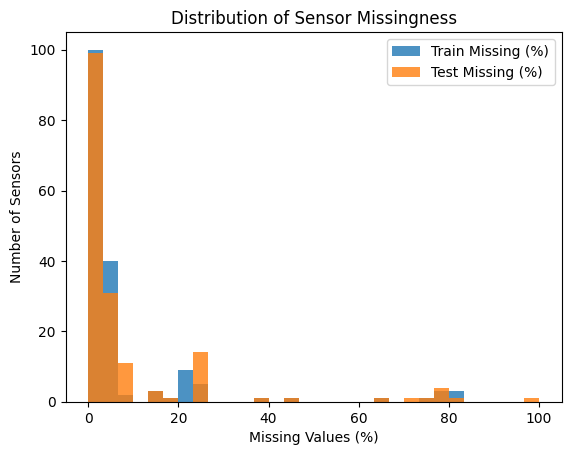

In [6]:
missing_data = pd.DataFrame({
    "Train Missing (%)": train_df[sensor_cols].isnull().mean() * 100,
    "Test Missing (%)": test_df[sensor_cols].isnull().mean() * 100
})

print("Total missing sensor values:")
print("Train:", train_df[sensor_cols].isnull().sum().sum())
print("Test:", test_df[sensor_cols].isnull().sum().sum())

plt.figure(figsize=(12, 5))

missing_data.plot(kind="hist", bins=30, alpha=0.8)
plt.title("Distribution of Sensor Missingness")
plt.xlabel("Missing Values (%)")
plt.ylabel("Number of Sensors")
plt.show()

In [7]:
print("Sensors with more than 50% missing values:")

high_missing = missing_data[missing_data["Train Missing (%)"] > 50].sort_values("Train Missing (%)", ascending=False)

display(high_missing.round(2))

print("Number of highly missing sensors:", len(high_missing))

Sensors with more than 50% missing values:


,Train Missing (%),Test Missing (%)
s166,82.64,80.56
s108,81.73,79.66
s121,80.11,77.98
s100,77.83,75.61
s021,77.38,76.78
s147,77.38,76.78
s072,73.91,71.66
s074,66.47,64.35


Number of highly missing sensors: 8


#### 4. Sensor Value Distribution:

In [8]:
display(train_df[sensor_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(2))

,mean,std,min,50%,max
s000,50567075.04,2.209220e+08,0.0,3350000.0,6.618810e+09
s001,4.23,9.062000e+01,0.0,0.0,1.411957e+04
s002,639160.57,1.312144e+08,0.0,0.0,2.696864e+10
s003,1.07,1.143000e+01,0.0,0.0,8.694200e+02
s004,1.21,5.807000e+01,0.0,0.0,7.027720e+03
...,...,...,...,...,...
s165,196.85,1.303290e+03,0.0,46.4,1.224202e+05
s166,4064781.45,3.637444e+06,0.0,2149512.0,8.597918e+06
s167,0.02,9.300000e-01,0.0,0.0,8.196000e+01
s168,117981.52,4.505931e+06,0.0,0.0,3.883306e+08


In [9]:
constant_sensors = [col for col in sensor_cols if train_df[col].nunique(dropna=True) <= 1]

print("Constant sensors:", constant_sensors)
print("Number of constant sensors:", len(constant_sensors))

Constant sensors: ['s146']
Number of constant sensors: 1


In [10]:
sensor_comparison = pd.DataFrame({
    "Train Mean": train_df[sensor_cols].mean(),
    "Test Mean": test_df[sensor_cols].mean(),
    "Train Std": train_df[sensor_cols].std(),
    "Test Std": test_df[sensor_cols].std()
})

sensor_comparison["Mean Difference (%)"] = (
    (sensor_comparison["Test Mean"] - sensor_comparison["Train Mean"]).abs()
    / (sensor_comparison["Train Mean"].abs() + 1e-8)
) * 100

display(sensor_comparison.sort_values("Mean Difference (%)", ascending=False).head(20).round(2))

,Train Mean,Test Mean,Train Std,Test Std,Mean Difference (%)
s062,313.96,19762.81,18635.61,41495.66,6194.72
s061,18554.08,772360.62,106187.88,1735568.15,4062.75
s064,1.27,21.46,94.09,1609.66,1585.19
s055,943.06,7939.12,2709.42,15514.39,741.85
s098,568.08,3302.33,44120.10,204230.13,481.32
s060,675986.01,3442895.66,1377493.73,8787810.36,409.31
s051,198.56,993.16,25460.89,80361.19,400.18
s005,2443.81,12029.68,189191.53,1069679.58,392.25
s022,3265.62,13238.19,217798.19,1288813.33,305.38
s110,3430.25,12791.66,137111.36,428664.28,272.91


### 5. EDA Summary

- The failure rate is highly imbalanced (0.71%).
- Repair costs are strongly right-skewed.
- Sensor features contain substantial missing values.
- Eight sensors have more than 50% missing values.
- One sensor (`s146`) is constant.
- Several sensors show substantial train–test differences, suggesting potential distribution shift between depots.

## 6. Feature Analysis (Member 3 - Shaik Mohd Aatiq)

Sections 1-5 cover the general EDA (target, repair cost, missing values). This section analyses the
**170 sensors** themselves:

| Section | Question |
|---|---|
| 6.1 | Which sensors carry predictive signal, through their values or their missingness? |
| 6.2 | Which sensors are low-variance or potentially noisy? |
| 6.3 | How correlated are the sensors, and which are redundant? |
| 6.4 | Do sensor distributions differ between train and test? |
| 6.5 | Are some test columns misaligned, and can they be fixed? |
| 6.6 | Is there a depot (population) shift between train and test? |
| 6.7 | Which sensors should be kept, dropped or tested for modelling? |

All logic lives in `src/feature_analysis.py`; this notebook calls it and shows the results.

> **Leakage note:** everything here is descriptive and computed on the full training data. It is not used
> to pick model features directly. Any supervised feature selection used for modelling is re-fitted inside
> each training fold of the shared 5-fold CV (`results/cv_folds.npz`), in `src/lightgbm_model.py`.

In [11]:
import src.feature_analysis as fa

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

sensors = fa.get_sensor_columns(train_df)
print("Sensors analysed:", len(sensors))

Sensors analysed: 170


### 6.1 Predictive Signal per Sensor

For each sensor we compute the **univariate AUC** of its raw value against `failure`
(missing values filled by the median). We report `max(AUC, 1 - AUC)`, so 0.5 means no signal and 1.0 means
perfect separation in either direction. We also compare the failure rate when the sensor is **missing**
vs **present**.

In [12]:
signal = fa.sensor_signal(train_df, sensors)

print("Sensors with AUC >= 0.90:", int((signal["auc_strength"] >= 0.90).sum()))
print("Sensors with AUC >= 0.80:", int((signal["auc_strength"] >= 0.80).sum()))
print(f"Sensors with AUC <  {fa.WEAK_SIGNAL_AUC}:", int((signal["auc_strength"] < fa.WEAK_SIGNAL_AUC).sum()))

display(signal.head(10))

Sensors with AUC >= 0.90: 43
Sensors with AUC >= 0.80: 66
Sensors with AUC <  0.52: 30


,auc_strength,direction,missing_frac,fail_rate_if_missing,fail_rate_if_present,missing_risk_ratio
sensor,,,,,,
s149,0.9723,higher = failure,0.0054,0.0132,0.0071,1.8772
s123,0.9723,higher = failure,0.0054,0.0132,0.0071,1.8772
s071,0.9685,higher = failure,0.0000,NaN,0.0071,NaN
s034,0.9664,higher = failure,0.0023,0.0465,0.0070,6.6462
s122,0.9430,higher = failure,0.0096,0.0355,0.0068,5.2111
s047,0.9389,higher = failure,0.0103,0.0348,0.0068,5.1136
s097,0.9383,higher = failure,0.0096,0.0355,0.0068,5.2111
s120,0.9363,higher = failure,0.0104,0.0343,0.0068,5.0427
s053,0.9357,higher = failure,0.0112,0.0335,0.0068,4.9404


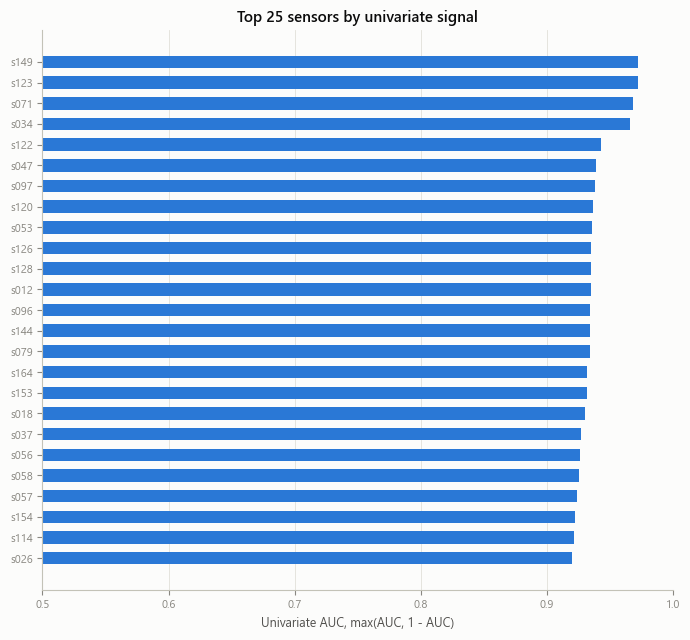

In [13]:
fa.plot_signal(signal, top=25);

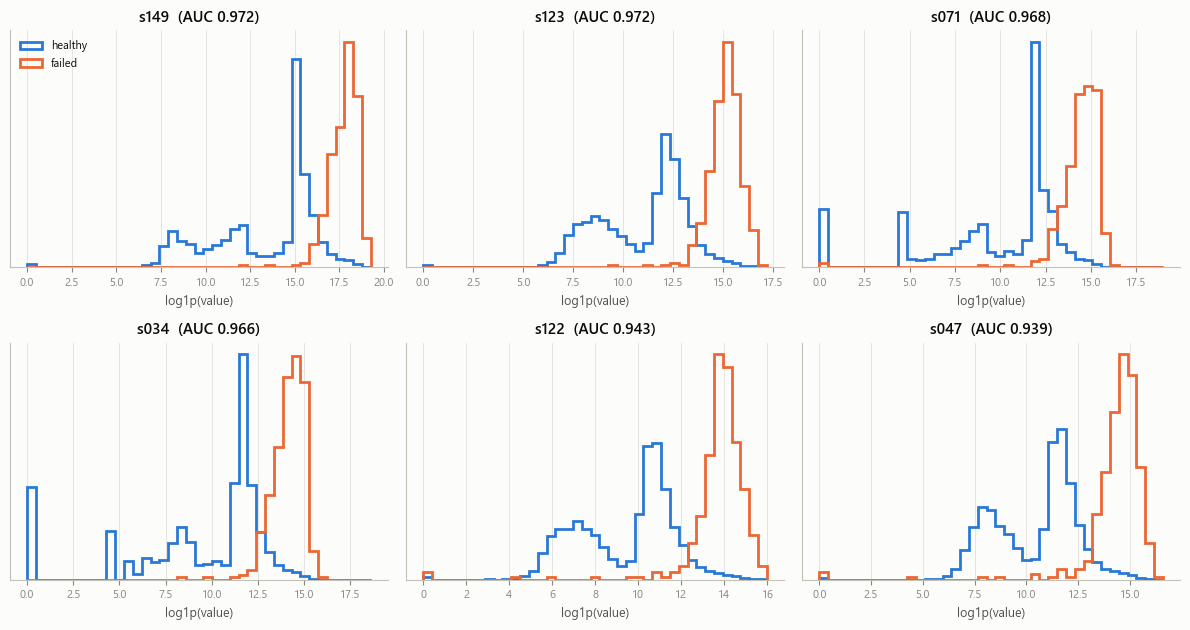

In [14]:
fa.plot_class_distributions(train_df, signal.index[:6].tolist(), signal);

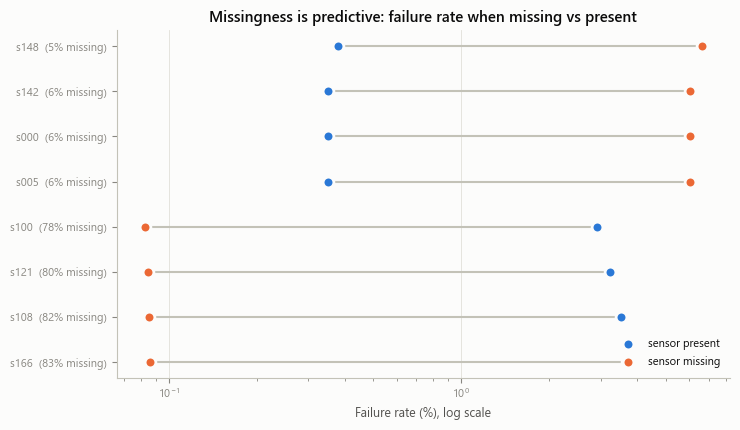

In [15]:
fa.plot_missingness_signal(signal, n=8);

**Takeaways**

- Many sensors are individually very strong: the best (s149, s123, s071, s034) reach an AUC of about 0.97,
  and 66 sensors exceed 0.80. On all 66 of them, failed vehicles have **higher** readings.
- About 30 sensors have almost no univariate signal (AUC < 0.52). They may still help in combination,
  so this alone is not a reason to drop them.
- **Missingness is informative in both directions.** When s166 / s108 / s121 are present the failure rate is
  about 3.5%, versus under 0.1% when they are missing (about 40x). For s142 / s148 / s152 it is the opposite:
  about 6% when missing vs 0.4% when present. Median imputation erases this signal; LightGBM keeps it by handling missing values natively.

### 6.2 Low-Variance and Potentially Noisy Sensors

Each sensor is flagged as:

- **constant**: at most one distinct observed value;
- **quasi-constant**: one value covers at least 99% of the observed rows;
- **high missing**: more than 50% missing in train;
- **weak signal**: univariate AUC below 0.52.

In [16]:
quality = fa.feature_quality(train_df, sensors, signal)

flag_counts = quality[["constant", "quasi_constant", "high_missing", "weak_signal"]].sum()
display(flag_counts.rename("n_sensors").to_frame())

print("Sensors with two or more flags:")
display(quality[quality["n_flags"] >= 2][
    ["n_unique", "top_value_freq", "missing_frac", "auc_strength", "category"]
])

,n_sensors
constant,1
quasi_constant,17
high_missing,8
weak_signal,30


Sensors with two or more flags:


,n_unique,top_value_freq,missing_frac,auc_strength,category
s147,58,0.9951,0.7738,0.5020,quasi-constant
s146,1,1.0000,0.0108,0.5000,constant
s036,2,0.9998,0.2457,0.5001,quasi-constant
s152,242,0.9944,0.0634,0.5014,quasi-constant
s064,62,0.9965,0.0634,0.5016,quasi-constant
s168,162,0.9959,0.0634,0.5019,quasi-constant
s019,49,0.9914,0.0430,0.5022,quasi-constant
s052,212,0.9953,0.0634,0.5022,quasi-constant
s167,24,0.9956,0.0430,0.5042,quasi-constant
s004,47,0.9949,0.0430,0.5051,quasi-constant


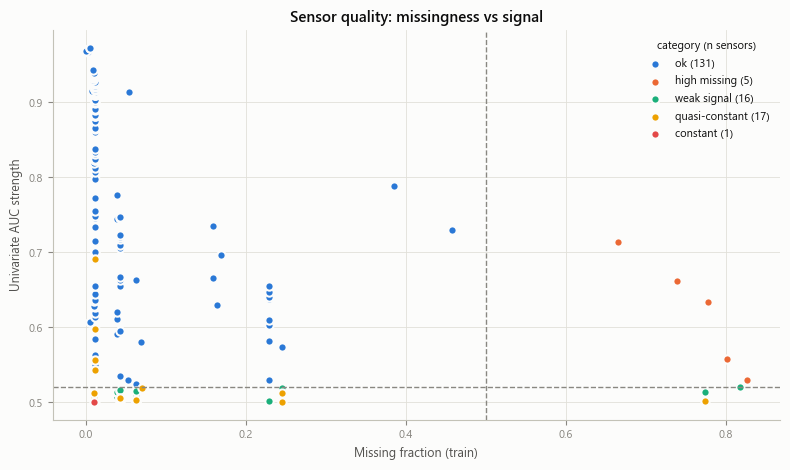

In [17]:
fa.plot_feature_quality(quality);

**Takeaways**

- `s146` is the only truly constant sensor (already removed by `src/preprocessing.py`).
- 17 sensors are **quasi-constant**: almost always the same value (usually 0). Most have no univariate signal, but
  one reaches an AUC of 0.69 through its rare non-zero values. So they are removal *candidates* to test in CV, not
  automatic drops.
- `s147` is both high-missing (77%) and quasi-constant, with no signal (AUC 0.50). It is the clearest noise sensor.
- The values of the eight high-missing sensors are weak predictors on their own (AUC 0.50-0.71), but **their
  missingness is strongly predictive** (6.1). They are not noise, especially for a model that sees missing values directly.

### 6.3 Sensor Correlations

We use **Spearman** correlation, because the sensors are heavily skewed (157 of 170 have |skew| > 5). Sensors with
|rho| > 0.95 are joined into **redundant groups**; within each group the sensor with the fewest missing
values is kept as its representative.

In [18]:
corr = fa.correlation_analysis(train_df, sensors)
pairs = corr["pairs"]

print("Sensor pairs with |rho| > 0.80:", int((pairs["abs_rho"] > 0.80).sum()))
print("Sensor pairs with |rho| > 0.95:", int((pairs["abs_rho"] > 0.95).sum()))
print("Redundant groups:", len(corr["groups"]), "| sensors removable (one kept per group):", len(corr["to_drop"]))

display(pairs.head(10))
display(corr["group_table"])

Sensor pairs with |rho| > 0.80: 1855
Sensor pairs with |rho| > 0.95: 170
Redundant groups: 13 | sensors removable (one kept per group): 51


,sensor_a,sensor_b,abs_rho
0,s012,s128,1.0000
1,s012,s126,1.0000
2,s126,s128,1.0000
3,s012,s120,1.0000
4,s120,s128,1.0000
5,s120,s126,1.0000
6,s079,s144,1.0000
7,s034,s071,0.9993
8,s153,s164,0.9968
9,s009,s105,0.9962


,size,kept,dropped
group,,,
1,20,s075,"s008, s037, s038, s039, s040, s041, s042, s055..."
2,18,s071,"s012, s018, s034, s047, s053, s079, s096, s097..."
3,4,s100,"s108, s121, s166"
4,3,s029,"s030, s031"
5,3,s081,"s082, s083"
6,2,s001,s102
7,2,s009,s105
8,2,s014,s065
9,2,s115,s028


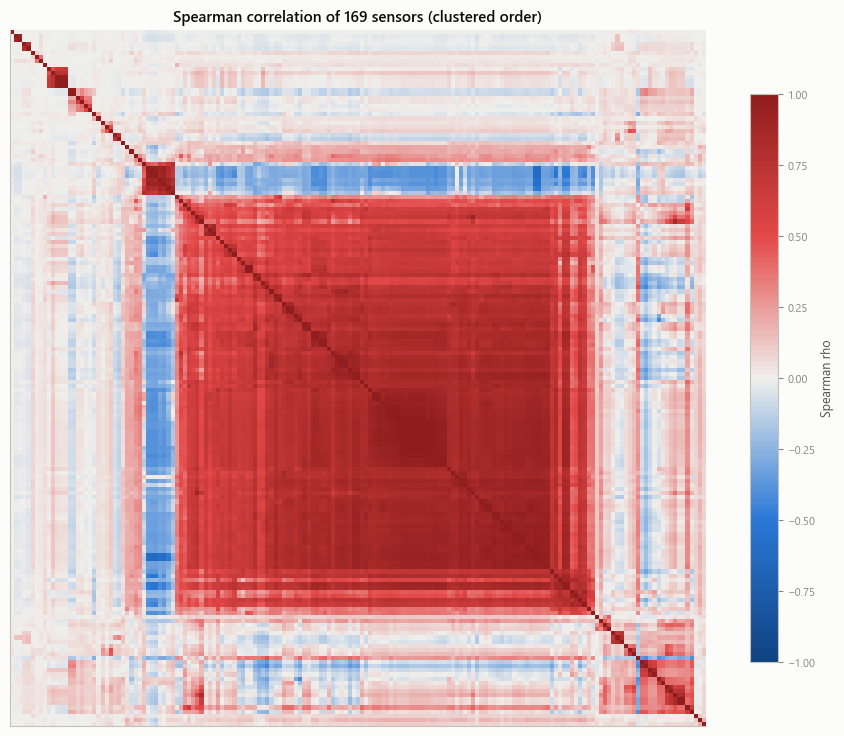

In [19]:
fa.plot_correlation_heatmap(corr['corr']);

**Takeaways**

- The sensors are highly redundant: 1,855 pairs exceed |rho| = 0.8, and 170 pairs exceed 0.95.
- The 0.95 pairs form 13 groups. Keeping one sensor per group would remove 51 sensors. The two largest groups have
  20 sensors (s008, s037-s042, ...) and 18 sensors (s012, s034, s047, s071, s120, ...). Within the second group,
  s012, s120, s126 and s128 are exactly proportional (rho = 1.000).
- Tree models such as LightGBM handle redundancy well, but it has two consequences:
  1. it **dilutes permutation importance**, because shuffling one sensor is covered by its duplicates, so
     importance should also be measured per group;
  2. it causes **multicollinearity** for Logistic Regression.

### 6.4 Train vs Test Sensor Distributions

Section 4 compared train and test **means**. Here each sensor's full distribution is compared with:

- the **KS statistic**: the maximum gap between the two cumulative distributions (0 = identical, 1 = no overlap);
- the **Population Stability Index (PSI)**: < 0.10 stable, 0.10-0.25 moderate, > 0.25 major shift.
  Missing values count as their own bin, so a change in the missing rate also counts as a shift.

In [20]:
shift_raw = fa.train_test_shift(train_df, test_df, sensors)

display(shift_raw["psi_band"].value_counts().rename("n_sensors").to_frame())
display(shift_raw.head(12)[["psi", "ks_stat", "train_missing", "test_missing", "train_median", "test_median"]])

,n_sensors
psi_band,
stable,158
major,11
moderate,1


,psi,ks_stat,train_missing,test_missing,train_median,test_median
sensor,,,,,,
s047,15.9161,NaN,0.0103,1.0000,"71,710.0000",NaN
s054,12.2836,0.9819,0.0112,0.0115,"4,050.0000",0.0000
s120,8.8225,0.7401,0.0104,0.0118,"10,183,000.0000","26,677,000.0000"
s056,4.2675,0.5604,0.0112,0.0115,"25,640.0000",480.0000
s062,3.6310,0.8041,0.0112,0.0115,59.0000,"8,059.0000"
s055,3.2989,0.7186,0.0112,0.0115,456.3000,"4,260.4000"
s061,1.8383,0.6071,0.0112,0.0115,"7,780.0000","321,760.0000"
s059,1.3871,0.4592,0.0112,0.0115,"1,550,700.0000","123,200.0000"
s060,1.2689,0.4141,0.0112,0.0115,"306,650.0000","1,630,430.0000"


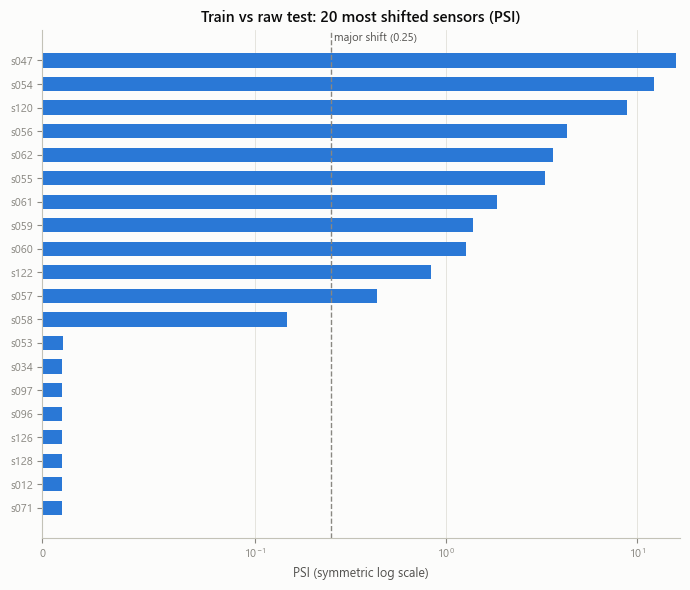

In [21]:
fa.plot_psi(shift_raw, top=20, title='Train vs raw test: 20 most shifted sensors (PSI)');

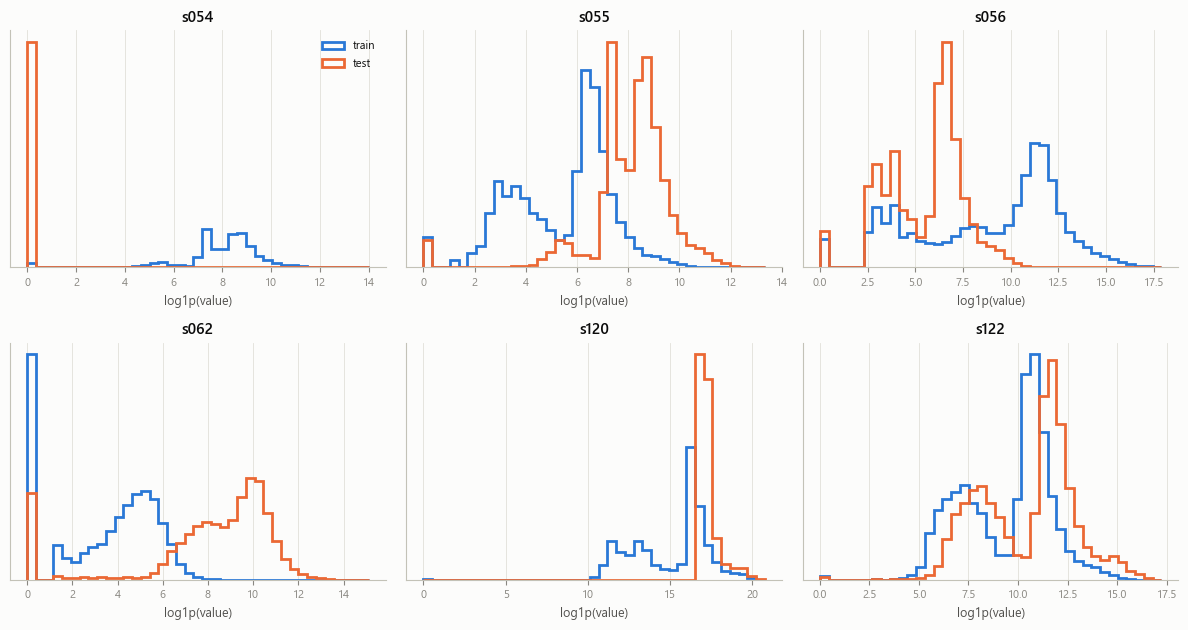

In [22]:
fa.plot_train_test_distributions(train_df, test_df, ["s054", "s055", "s056", "s062", "s120", "s122"]);

**Takeaways**

- 158 of 170 sensors are stable. The other 12 shift (11 of them majorly), with PSI up to 16 and KS up to 0.98,
  meaning the train and test values barely overlap.
- `s047` is **missing for 100% of test vehicles** but only about 1% of training vehicles.
- The shifted sensors are not spread randomly: they form a consecutive block (s054-s063) plus s047, s120 and
  s122. A real depot or population change would shift many sensors a little. This pattern looks like a
  **data-processing problem in the test file**, which 6.5 investigates.

### 6.5 Test-Set Sensor Misalignment

Each test column is compared against **every** training column with the KS statistic. A mismatch is reported when
a different training column fits clearly better than the column's own.

In [23]:
mismatches = fa.detect_column_mismatches(train_df, test_df, sensors)
display(mismatches[mismatches["mismatch"]])

,best_train_match,ks_best,ks_own,mismatch,note
test_sensor,,,,,
s047,None,NaN,NaN,True,all missing in test
s054,s036,0.0004,0.9814,True,
s055,s054,0.0312,0.7234,True,
s056,s055,0.0446,0.5602,True,
s057,s056,0.0270,0.2796,True,
s058,s057,0.0682,0.1242,True,
s059,s058,0.0334,0.4624,True,
s060,s059,0.0252,0.4134,True,
s061,s060,0.0268,0.6050,True,


Rows whose `ks_own` is already small (for example s144, 0.05) are near-ties between correlated sensors, not
misalignments. The heatmap below zooms into the s054-s063 block:

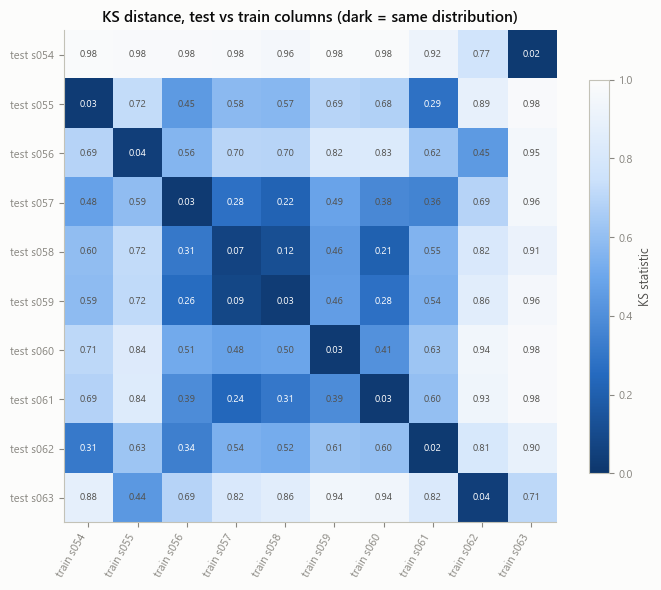

In [24]:
block_ks = fa.block_ks_matrix(train_df, test_df)
fa.plot_block_ks(block_ks);

The dark cells sit **one step to the right of the diagonal**: test `s055` matches train `s054`, test `s056` matches
train `s055`, and so on. Test `s054` is all zeros.

Next, `s047` and `s122`. Both are closely related to `s012`, so the ratio `sensor / s012` shows which sensor a
column really contains:

In [25]:
ratios = pd.DataFrame({
    "train s047 / s012": fa.ratio_to_s012(train_df, "s047"),
    "train s122 / s012": fa.ratio_to_s012(train_df, "s122"),
    "test s122 / s012": fa.ratio_to_s012(test_df, "s122"),
})
ratios.index = [f"q{int(q * 100)}" for q in ratios.index]
display(ratios.T)

,q10,q25,q50,q75,q90
train s047 / s012,0.0097,0.0123,0.0165,0.0250,0.0395
train s122 / s012,0.0037,0.0047,0.0063,0.0087,0.0119
test s122 / s012,0.0093,0.0119,0.0160,0.0222,0.0304


Test `s122` has the same ratio profile as train **s047**, not train s122, so the test file holds s047's values in
the s122 column. Finally, `s120`. In train, `s120 = 1.7416 x s012` almost exactly:

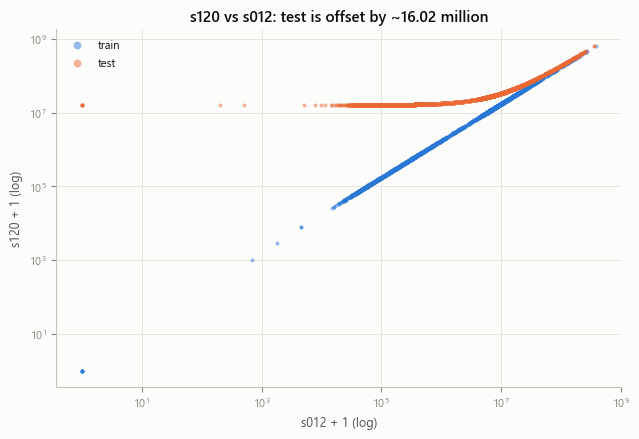

In [26]:
fa.plot_s120_offset(train_df, test_df);

In test, every vehicle sits on a parallel line: `s120` has a constant of about **16.02 million** added.

**Fix: `align_test_sensors()`** maps the test columns back:

| Problem | Fix | Lost in test |
|---|---|---|
| s055-s063 hold s054-s062 | shift the block back by one column | s063 (train s063 is almost always 0) |
| s122 holds s047's values | s047 <- test s122 | s122 |
| s120 has a +16.02M offset | subtract the estimated offset | - |

In [27]:
test_aligned = fa.align_test_sensors(test_df, train_df)
lost = fa.find_unavailable_in_test(train_df, test_aligned, sensors)
shift_aligned = fa.train_test_shift(train_df, test_aligned, sensors).drop(index=lost)

print("Sensors unavailable in the aligned test set:", lost)
display(pd.DataFrame({
    "raw test": shift_raw["psi_band"].value_counts(),
    "aligned test": shift_aligned["psi_band"].value_counts(),
}))
print(f"Max PSI after alignment: {shift_aligned['psi'].max():.3f} ({shift_aligned['psi'].idxmax()})")

Sensors unavailable in the aligned test set: ['s063', 's122']


,raw test,aligned test
psi_band,,
stable,158,168
moderate,1,0
major,11,0


Max PSI after alignment: 0.059 (s047)


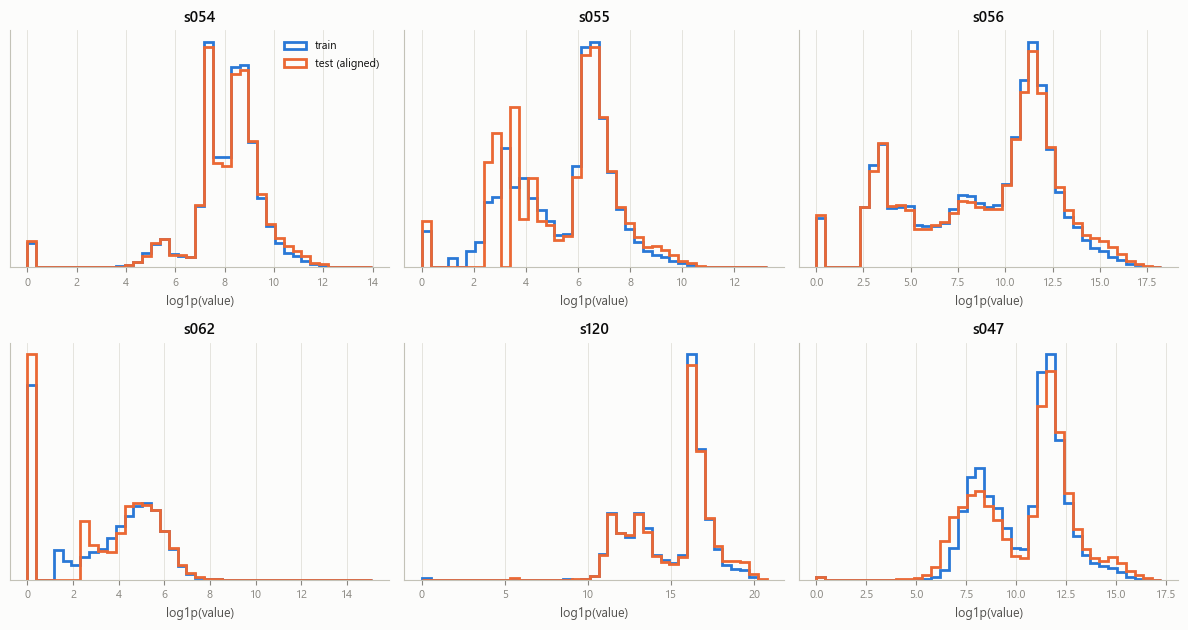

In [28]:
fa.plot_train_test_distributions(
    train_df, test_aligned, ["s054", "s055", "s056", "s062", "s120", "s047"], test_label="test (aligned)"
);

**Takeaways**

- After alignment, **all 168 remaining sensors are stable** (before: 11 major and 1 moderate shift; the largest PSI
  is now 0.06), and the distributions overlap again.
- **Every model's test predictions should use `align_test_sensors(test_df, train_df)`.** Several of the affected sensors
  (s047, s120, s122) are among the most predictive, so a model scored on the raw test file receives wrong inputs.
  This probably explains part of the gap between the V1 baseline's validation cost (12,210 on 11,200 vehicles) and its
  Kaggle score (84,066 on 20,000 vehicles).
- `s063` and `s122` cannot be recovered in test, so they must be dropped as model features.

### 6.6 Potential Depot Distribution Shift

The data has **no depot column**, so a depot (population) shift is tested indirectly, on the **aligned** test set:

1. **Adversarial validation:** a LightGBM model tries to tell train rows from test rows. AUC 0.5 = indistinguishable.
2. **Latent groups:** vehicles are clustered (KMeans) by sensor values and by missingness pattern, as a stand-in for
   depots. Then we compare whether train and test contain the groups in the same proportions.
3. **Predicted-risk shift:** a failure model trained on train is applied to test, to see whether test vehicles look more
   failure-prone.

In [29]:
usable = [c for c in sensors if c not in lost and c not in fa.CONSTANT_SENSORS]

adv_raw = fa.adversarial_validation(train_df, test_df, sensors)
adv_aligned = fa.adversarial_validation(train_df, test_aligned, usable)

display(pd.DataFrame({
    "adversarial AUC": [adv_raw["auc"], adv_aligned["auc"]],
    "top drivers": [", ".join(f"{s} ({v:.0%})" for s, v in a["importance"].head(4).items())
                    for a in (adv_raw, adv_aligned)],
    "test-likeness of healthy train vehicles": [adv_raw["testlikeness_healthy"], adv_aligned["testlikeness_healthy"]],
    "test-likeness of failed train vehicles": [adv_raw["testlikeness_failed"], adv_aligned["testlikeness_failed"]],
}, index=["raw test", "aligned test"]))

,adversarial AUC,top drivers,test-likeness of healthy train vehicles,test-likeness of failed train vehicles
raw test,1.0000,"s047 (87%), s054 (10%), s120 (0%), s096 (0%)",0.0010,0.0016
aligned test,0.9771,"s062 (32%), s055 (31%), s018 (7%), s057 (6%)",0.1088,0.3051


In [30]:
groups = fa.latent_groups(train_df, test_aligned, sensors)

for view, g in groups.items():
    print(f"Latent groups from sensor {view}: k = {g['best_k']}, "
          f"train-vs-test Cramer's V = {g['cramers_v']:.3f}")
    display(g["profile"])

Latent groups from sensor values: k = 2, train-vs-test Cramer's V = 0.007


,train_share,test_share,failure_rate,n_failures,median_repair_cost
cluster,,,,,
0,0.3903,0.3829,0.0007,15,350.0000
1,0.6097,0.6171,0.0112,382,172.0000


Latent groups from sensor missingness: k = 4, train-vs-test Cramer's V = 0.022


,train_share,test_share,failure_rate,n_failures,median_repair_cost
cluster,,,,,
1,0.7474,0.7373,0.0024,102,234.0000
0,0.0112,0.0115,0.0032,2,650.5000
3,0.2018,0.2016,0.0120,136,202.5000
2,0.0396,0.0495,0.0708,157,139.0000


Failure model OOF AUC: 0.984 | mean risk test / train: 3.15x


,mean_predicted_risk,share_risk_above_0.1,share_risk_above_0.5
train (out-of-fold),0.0055,0.0104,0.0044
test (aligned),0.0173,0.0321,0.0158


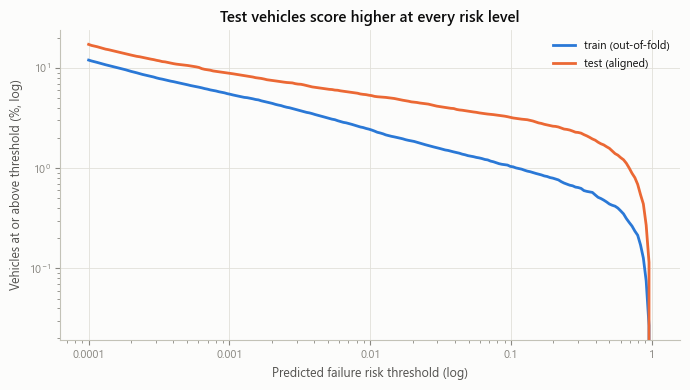

In [31]:
risk = fa.predicted_risk_shift(train_df, test_aligned, usable)
print(f"Failure model OOF AUC: {risk['oof_auc']:.3f} | mean risk test / train: {risk['ratio']:.2f}x")
display(risk["table"])
fa.plot_risk_distribution(risk);

**Takeaways**

- On the raw test file, train and test are perfectly separable (AUC 1.000), almost entirely because of the misaligned
  sensors (s047, s054).
- After alignment the per-sensor distributions match (6.5), but train and test are still separable (AUC about 0.98)
  through combinations of sensors (s055, s062, s018, ...). **Failed** training vehicles look about 3x more "test-like"
  than healthy ones.
- The latent groups appear in **the same proportions** in train and test (Cramer's V < 0.03). So no particular group of
  vehicles is over- or under-represented in test, even though failure rates differ strongly between groups
  (0.07% to 7%).
- The failure model predicts about **3x higher average risk** for test vehicles. At every risk level a larger share of
  test vehicles scores above it, and the gap widens for high-risk vehicles: about 1.4x at risk >= 0.0001 and about
  3.5x at risk >= 0.3.
- **Interpretation:** the test vehicles are consistent with a different depot or population whose vehicles are more
  heavily used and more failure-prone. Two consequences for modelling:
  1. a threshold chosen on CV will probably flag **too few** test vehicles if it is applied blindly, so the expected
     test inspection rate should be checked;
  2. CV cost is an optimistic estimate of test cost.

### 6.7 Feature Analysis Summary and Recommendations

Redundant groups are recomputed so that a sensor unavailable in test is never chosen as a group's representative.

In [32]:
corr_rec = fa.correlation_analysis(train_df, sensors, exclude=lost)
recommendations = fa.feature_recommendations(quality, corr_rec, lost)

summary = (
    recommendations[recommendations["action"] != "keep"]
    .rename_axis("sensor").reset_index()
    .groupby("action")
    .agg(n_sensors=("sensor", "size"), sensors=("sensor", lambda s: ", ".join(sorted(s))))
)
print("Sensors kept as they are:", int((recommendations["action"] == "keep").sum()))
with pd.option_context("display.max_colwidth", None):
    display(summary)

Sensors kept as they are: 100


,n_sensors,sensors
action,,
candidate: quasi-constant,17,"s004, s019, s036, s051, s052, s064, s080, s089, s098, s109, s110, s124, s147, s152, s167, s168, s169"
candidate: redundant (|rho| > 0.95),50,"s008, s012, s018, s028, s030, s031, s034, s037, s038, s039, s040, s041, s042, s047, s053, s055, s057, s058, s059, s065, s073, s079, s082, s083, s095, s096, s097, s101, s102, s105, s108, s120, s121, s123, s126, s128, s131, s141, s144, s149, s151, s153, s154, s155, s156, s157, s158, s159, s164, s166"
drop: constant,1,s146
drop: unavailable in test,2,"s063, s122"


**Feature analysis summary**

| Finding | Evidence | Action for modelling |
|---|---|---|
| Test sensors are misaligned | s054-s063 shifted by one column, s047 moved to s122, s120 offset by 16.02M | Use `align_test_sensors()` for **all** test predictions |
| Sensors unavailable in test | s063 and s122 are empty after alignment | **Drop** |
| Constant sensor | s146 | **Drop** |
| Quasi-constant sensors | 17 sensors, one value in >= 99% of rows | Removal candidates, tested in CV |
| Redundant sensors | 13 groups with \|rho\| > 0.95, 50 removable (keeping a test-available sensor per group) | Removal candidates; grouped permutation importance |
| Informative missingness | Failure rate differs up to about 40x between missing and present | Keep missing values for LightGBM (no imputation) |
| Strong univariate sensors | 66 sensors with AUC >= 0.80 | Expect strong tree-model performance |
| Depot / population shift | Adversarial AUC about 0.98 after alignment; test risk about 3x higher | Treat CV cost as optimistic; check the test inspection rate |

These candidates feed the **"LightGBM with selected features"** experiment. The selection (low-variance filter,
correlation filter, importance ranking) is re-fitted **inside each CV training fold** of the shared folds, so the
validation fold never influences which features are chosen.